# EHT Black Hole: Closure-Only VLBI Imaging


<!-- inverse-evidence-audit:20261026:start -->

> **本次维护说明：** 本Notebook本轮在隔离副本中完整重新执行四种本地反演，并新增本轮四个空间恢复结果、带符号残差与完整精度指标。保留的上游空间面板仍属历史方法参考；模拟GT不是真实黑洞实测真值。

### 观测到目标核查卡

当前存在 `data/raw_data.npz`；所述获取/估计路径由本地代码实现。

任务 `eht_black_hole_original` 的观测定义：当前raw_data.npz的实际键、形状、dtype与README单位说明：vis_corrupt (1, 421) complex128：Measured gain-corrupted visibility, Jy.；uv_coords (1, 421, 2) float64：Visibility $(u,v)$ coordinates, wavelengths.；sigma_vis (1, 421) float64：Baseline thermal-noise standard deviation, Jy.；station_ids (1, 421, 2) int64：Zero-based station pair indices, dimensionless.；cp_corrupt_values_deg (1, 269) float64：Measured closure phase, degrees.；cp_corrupt_sigmas_deg (1, 269) float64：Closure-phase uncertainty, degrees.；cp_u1 (1, 269, 2) float64：First directed triangle baseline $(u,v)$, wavelengths.；cp_u2 (1, 269, 2) float64：Second directed triangle baseline $(u,v)$, wavelengths.；cp_u3 (1, 269, 2) float64：Third directed triangle baseline $(u,v)$, wavelengths.；lca_corrupt_values (1, 233) float64：Measured log closure amplitude, dimensionless.；lca_corrupt_sigmas (1, 233) float64：Log closure amplitude uncertainty, dimensionless.；lca_u1 (1, 233, 2) float64：First quadrangle baseline $(u,v)$, wavelengths.；lca_u2 (1, 233, 2) float64：Second quadrangle baseline $(u,v)$, wavelengths.；lca_u3 (1, 233, 2) float64：Third quadrangle baseline $(u,v)$, wavelengths.；lca_u4 (1, 233, 2) float64：Fourth quadrangle baseline $(u,v)$, wavelengths.。恢复目标：64x64射电亮度图，Jy/pixel。

获取模型：离散三角像素Fourier可见度受站增益腐蚀；closure相位/幅度消去理想站增益。实际恢复算法：main.run_reconstruction及ClosureRMLSolver：正值log参数、closure loss和entropy的L-BFGS优化。语义类型为 `inverse_spatial`；其中闭式逆也属于反问题，但内部制造观测或缺输入的限制见下文。

真值情况：独立于本次重建的仿真设定真值；evaluation/validation.md:3说明64x64模拟真值来自原资产archive，不能称真实黑洞测量真值。评估方法参考与仪器校准均不能当作独立物理真值。

现有实验和图：eht_black_hole_original.ipynb单元0：5. Results；eht_black_hole_original.ipynb单元8：Results: Calibrated Data；eht_black_hole_original.ipynb单元10：Results: Gain-Corrupted Data。图/比较代码位于单元4, 5, 13（从0计数）。原始11个代码单元逐字保留，并新增1个新计算空间比较单元；完整执行记录以本文件实际execution_count和输出为准。

本轮实际完整执行四方法，各三轮、每轮最多300步；新版完整执行后保留原六图及新增空间图。

限制与缺口：保留的cells9/11/13仍优先展示archived图；Conclusion前新增面板全部使用本轮results与标准提交fresh。独立原始ehtim重跑仍未验证。

<!-- inverse-evidence-audit:20261026:end -->


## 1. Problem


This notebook demonstrates the key result from **Chael et al. (2018), ApJ 857:23**:
closure-only imaging is robust to station-based gain errors, while traditional
visibility imaging fails catastrophically.

We compare two imaging strategies on synthetic EHT M87* data:

| Method | Data terms | Gain-robust? |
|--------|-----------|-------------|
| **Visibility RML** | Complex visibilities | No |
| **Closure-only** | Closure phases + log closure amplitudes | **Yes** |

Each method is tested on both **calibrated** and **gain-corrupted** observations.

This notebook loads archived reference results from `notebooks/reference_outputs/`
and actively runs the four cleaned-code comparisons below.

## 2. Data

### Load Data

The public observation contains 421 gain-corrupted baselines from a seven-station, 230 GHz array and the corresponding closure quantities. Calibrated measurements are retained only in the maintainer reference archive for the original controlled comparison. The notebook reads these hidden arrays separately; they are not solver inputs.



`data/raw_data.npz` contains one observation batch. Closure quantities and their UV legs come from the same gain-corrupted acquisition; no calibrated visibilities are supplied.

| Key | Shape | Dtype | Description |
| --- | --- | --- | --- |
| `vis_corrupt` | `(1, 421)` | complex128 | Measured gain-corrupted visibility, Jy. |
| `uv_coords` | `(1, 421, 2)` | float64 | Visibility $(u,v)$ coordinates, wavelengths. |
| `sigma_vis` | `(1, 421)` | float64 | Baseline thermal-noise standard deviation, Jy. |
| `station_ids` | `(1, 421, 2)` | int64 | Zero-based station pair indices, dimensionless. |
| `cp_corrupt_values_deg` | `(1, 269)` | float64 | Measured closure phase, degrees. |
| `cp_corrupt_sigmas_deg` | `(1, 269)` | float64 | Closure-phase uncertainty, degrees. |
| `cp_u1` | `(1, 269, 2)` | float64 | First directed triangle baseline $(u,v)$, wavelengths. |
| `cp_u2` | `(1, 269, 2)` | float64 | Second directed triangle baseline $(u,v)$, wavelengths. |
| `cp_u3` | `(1, 269, 2)` | float64 | Third directed triangle baseline $(u,v)$, wavelengths. |
| `lca_corrupt_values` | `(1, 233)` | float64 | Measured log closure amplitude, dimensionless. |
| `lca_corrupt_sigmas` | `(1, 233)` | float64 | Log closure amplitude uncertainty, dimensionless. |
| `lca_u1` | `(1, 233, 2)` | float64 | First quadrangle baseline $(u,v)$, wavelengths. |
| `lca_u2` | `(1, 233, 2)` | float64 | Second quadrangle baseline $(u,v)$, wavelengths. |
| `lca_u3` | `(1, 233, 2)` | float64 | Third quadrangle baseline $(u,v)$, wavelengths. |
| `lca_u4` | `(1, 233, 2)` | float64 | Fourth quadrangle baseline $(u,v)$, wavelengths. |

### Acquisition metadata

| Parameter | Value | Unit | Meaning |
| --- | --- | --- | --- |
| Image grid | 64 x 64 | pixels | Square sky brightness field. |
| Pixel pitch | 2.0 | microarcseconds/pixel | Angular separation of adjacent pixel centers. |
| Pixel pitch in radians | 9.696273622188272e-12 | radians/pixel | Acquisition constant used by the Fourier grid; preserve this supplied precision. |
| Pixel coordinates | $l=(31.5-q)\Delta$, $m=(31.5-p)\Delta$ | radians | Row $p$ and column $q$ run from 0 to 63; $\Delta=2$ microarcseconds. |
| Fourier sign | positive | dimensionless | Exponent uses $+2\pi i(ul+vm)$. |
| Pixel response | triangular | dimensionless | Separable triangular pulse in image space. |
| Total source flux | 0.6 | Jy | Known integrated flux for physical output scaling. |
| Observing frequency | 230.0 | GHz | Radio observing frequency. |
| Stations | 7 | stations | Indexed by `station_ids`. |
| Visibilities | 421 | baselines | Samples in this observation. |
| Boundary | finite field | dimensionless | No periodic image extension is assumed by the forward model. |

## 3. Physics

### Closure Quantities: Gain Invariance

Closure phases and log closure amplitudes cancel station-based gains:
**Closure phase**: $\phi_C = \arg(V_{ij} V_{jk} V_{ki})$ -- gains cancel in the triple product
**Log closure amplitude**: $\log|V_{ij}| + \log|V_{kl}| - \log|V_{ik}| - \log|V_{jl}|$ -- gain factors cancel

Below we show that visibility amplitudes are corrupted by gains, but closure
quantities remain nearly identical between calibrated and corrupted data.

Let $x_p$ be nonnegative sky brightness in Jy/pixel at angular pixel coordinate $r_p$, $u_m$ a baseline in wavelengths and $A$ the calibrated Fourier operator including its pixel pulse. Visibilities are $V_m=(Ax)_m$. Station gains multiply a baseline by $g_i\bar g_j$; triangle phase and quadrangle amplitude ratios cancel station-based phase/amplitude factors:

$$
\phi_{ijk}=\arg(V_{ij}V_{jk}V_{ki}),\qquad \ell_{ijkl}=\log|V_{ij}|+\log|V_{kl}|-\log|V_{ik}|-\log|V_{jl}|.
$$

These closures discard information and leave image ambiguity; a known flux or image prior supplies constraints rather than additional sky measurements. Angular labels are microarcseconds; model coordinates use the acquisition's calibrated units.

## 4. Method

### Image Reconstruction

We compare two methods on both calibrated and corrupted data:
- **Vis RML**: minimizes visibility chi-squared + entropy regularizers
- **Closure-only**: minimizes closure phase + log closure amplitude chi-squared + entropy regularizers

Both use Gull-Skilling entropy (`gs=1`) and simple entropy (`simple=10`) as regularizers,
optimized with L-BFGS-B in log-image space (matching ehtim's default).

The preceding cell loads upstream images; the next active cell reconstructs four cleaned-code comparisons. Read their provenance separately: the loaded image panels are not replaced by the fresh arrays.

## 5. Results

The four local reconstructions are actively computed by the retained solver cell. Most spatial comparison panels deliberately show archived upstream images, while the summary metrics and paired bars distinguish those from fresh cleaned-code results. Original historical scores are kept separately; they cannot establish parity for a different numerical environment.


In [1]:
import json
import sys
from pathlib import Path

import numpy as np
import matplotlib.pyplot as plt

TASK_DIR = Path.cwd().resolve().parent
sys.path.insert(0, str(TASK_DIR))

from src.preprocessing import load_observation, load_metadata
from src.visualization import compute_metrics, print_metrics_table, plot_uv_coverage, plot_comparison

REF_DIR = TASK_DIR / 'notebooks' / 'reference_outputs'
DATA_DIR = TASK_DIR / 'data'
%matplotlib inline
plt.rcParams.update({'font.size': 10, 'figure.dpi': 120})

In [2]:
obs = load_observation(str(DATA_DIR))
meta = load_metadata(str(DATA_DIR))
N = meta['N']
psize = meta['pixel_size_rad']
pixel_uas = meta['pixel_size_uas']
total_flux = meta['total_flux']
fov = N * pixel_uas
hw = fov / 2
with np.load(REF_DIR / 'reference_results.npz', allow_pickle=False) as saved:
    comparison = {key: saved[key] for key in saved.files}
print(f'Grid: {N} x {N}; pitch: {pixel_uas} microarcseconds; flux: {total_flux} Jy')
print(f'Baselines: {len(obs["uv_coords"])}; stations: {meta["n_stations"]}')
print(f'Closure phases: {len(obs["cp_corrupt_values_deg"])}; log closure amplitudes: {len(obs["lca_corrupt_values"])}')

Grid: 64 x 64; pitch: 2.0 microarcseconds; flux: 0.6 Jy
Baselines: 421; stations: 7
Closure phases: 269; log closure amplitudes: 233


### Ground Truth & UV Coverage


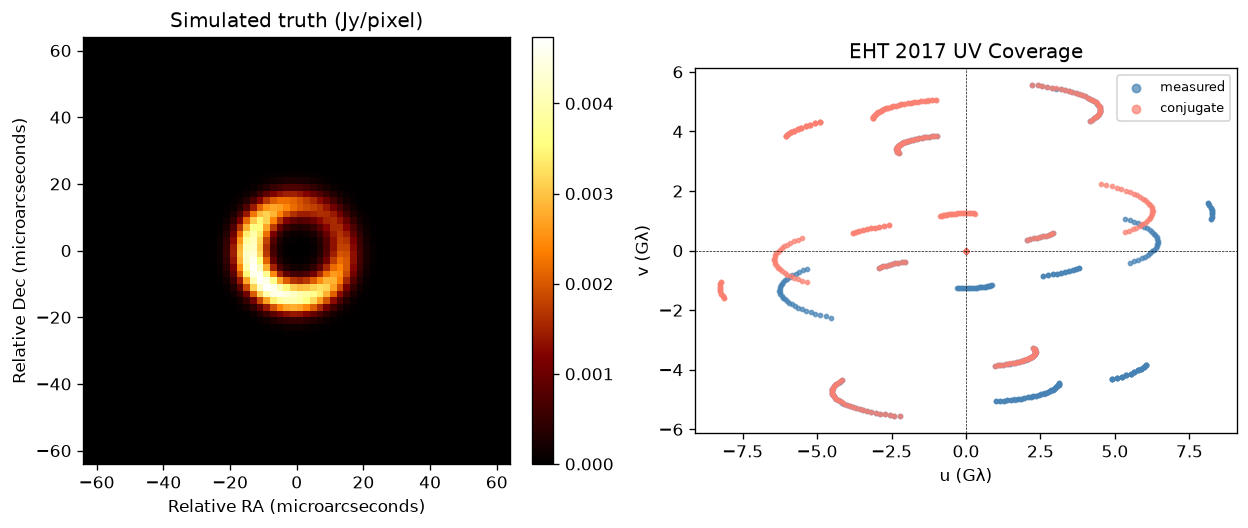

In [3]:
with np.load(TASK_DIR / 'evaluation' / 'ground_truth.npz', allow_pickle=False) as hidden:
    gt = hidden['reconstruction'][0]

fig, axes = plt.subplots(1, 2, figsize=(11, 4.5))
im = axes[0].imshow(gt, cmap='afmhot', origin='lower', extent=[-hw, hw, -hw, hw])
axes[0].set(xlabel='Relative RA (microarcseconds)', ylabel='Relative Dec (microarcseconds)', title='Simulated truth (Jy/pixel)')
plt.colorbar(im, ax=axes[0], fraction=0.046, pad=0.04)
plot_uv_coverage(obs['uv_coords'], title='EHT 2017 UV Coverage', ax=axes[1])
plt.tight_layout()
plt.show()

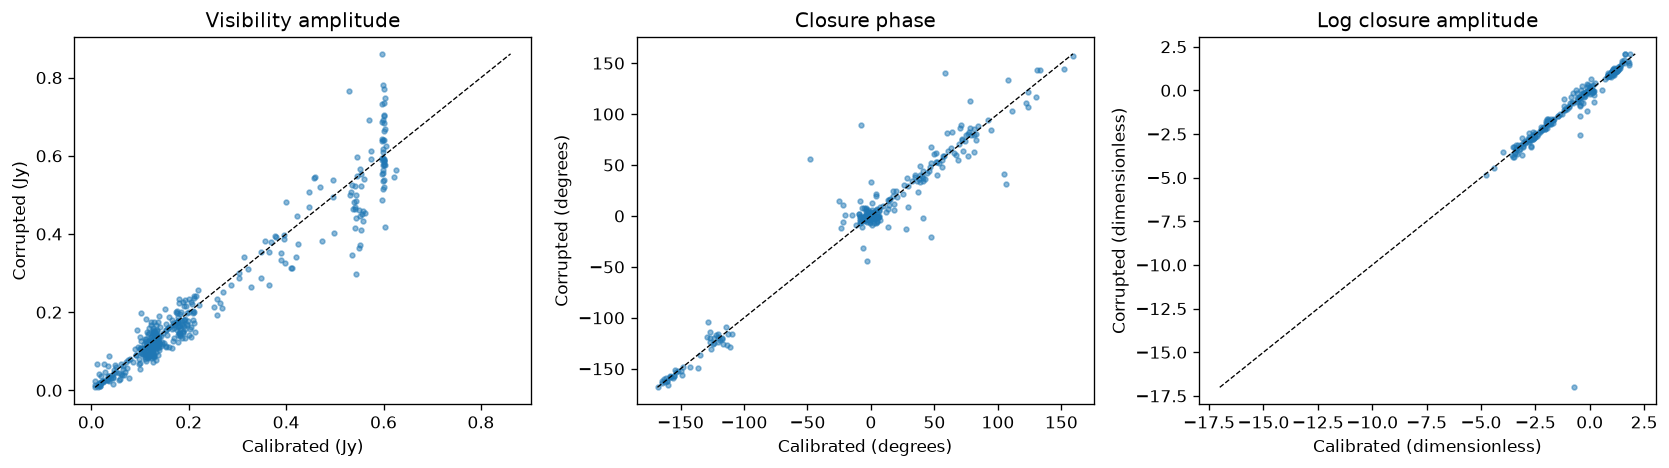

Visibility amplitude RMSD: 0.0495 Jy
Closure phase RMSD: 15.77 degrees
Log closure amplitude RMSD: 1.0999


In [4]:
amp_cal = np.abs(comparison['vis_cal'])
amp_cor = np.abs(obs['vis_corrupt'])
cp_cal = comparison['cp_values_deg']
cp_cor = obs['cp_corrupt_values_deg']
lca_cal = comparison['lca_values']
lca_cor = obs['lca_corrupt_values']

fig, axes = plt.subplots(1, 3, figsize=(14, 4))
for ax, left, right, title, unit in zip(
    axes, (amp_cal, cp_cal, lca_cal), (amp_cor, cp_cor, lca_cor),
    ('Visibility amplitude', 'Closure phase', 'Log closure amplitude'),
    ('Jy', 'degrees', 'dimensionless'),
):
    ax.scatter(left, right, s=8, alpha=0.5)
    lo = min(left.min(), right.min())
    hi = max(left.max(), right.max())
    ax.plot([lo, hi], [lo, hi], 'k--', lw=0.8)
    ax.set(xlabel=f'Calibrated ({unit})', ylabel=f'Corrupted ({unit})', title=title)
plt.tight_layout()
plt.show()
print(f'Visibility amplitude RMSD: {np.sqrt(np.mean((amp_cal - amp_cor)**2)):.4f} Jy')
print(f'Closure phase RMSD: {np.sqrt(np.mean((cp_cal - cp_cor)**2)):.2f} degrees')
print(f'Log closure amplitude RMSD: {np.sqrt(np.mean((lca_cal - lca_cor)**2)):.4f}')

In [5]:
ref_keys = {
    'Vis RML (cal)': 'vis_rml_cal',
    'Vis RML (corrupt)': 'vis_rml_corrupt',
    'Closure-only (cal)': 'closure_only_cal',
    'Closure-only (corrupt)': 'closure_only_corrupt',
    'Amp+CP (cal)': 'amp_cp_cal',
    'Amp+CP (corrupt)': 'amp_cp_corrupt',
}
ehtim_results = {name: comparison[key] for name, key in ref_keys.items()}
with (REF_DIR / 'reference_metrics.json').open(encoding='utf-8') as handle:
    ehtim_metrics = json.load(handle)
print(f'Loaded {len(ehtim_results)} archived standard-method results.')

Loaded 6 archived standard-method results.


In [6]:
# Calibrated observations are hidden maintainer comparison inputs.
review_obs = {**obs, **comparison}

# Run the original four cleaned-code comparisons from scratch.
from src.physics_model import ClosureForwardModel
from src.solvers import ClosureRMLSolver

# Build forward model
model = ClosureForwardModel(
    uv_coords=review_obs['uv_coords'], N=N, pixel_size_rad=psize,
    triangles=np.zeros((0, 3), dtype=int),
    quadrangles=np.zeros((0, 4), dtype=int),
)

# Gaussian prior
uas_to_rad = np.pi / (180 * 3600 * 1e6)
fwhm_rad = 20.0 * uas_to_rad
sigma_prior = fwhm_rad / (2 * np.sqrt(2 * np.log(2)))
coords_rad = (np.arange(N) - N / 2) * psize
xx, yy = np.meshgrid(coords_rad, coords_rad)
prior = np.exp(-(xx**2 + yy**2) / (2 * sigma_prior**2))
prior *= total_flux / prior.sum()

reg = {'gs': 1, 'simple': 10}

# Calibrated closure data
obs_data_cal = {
    'vis_obs': review_obs['vis_cal'], 'sigma_vis': review_obs['sigma_vis'],
    'cp_values_deg': review_obs['cp_values_deg'], 'cp_sigmas_deg': review_obs['cp_sigmas_deg'],
    'cp_u1': review_obs['cp_u1'], 'cp_u2': review_obs['cp_u2'], 'cp_u3': review_obs['cp_u3'],
    'lca_values': review_obs['lca_values'], 'lca_sigmas': review_obs['lca_sigmas'],
    'lca_u1': review_obs['lca_u1'], 'lca_u2': review_obs['lca_u2'],
    'lca_u3': review_obs['lca_u3'], 'lca_u4': review_obs['lca_u4'],
}
# Corrupted closure data
obs_data_corrupt = {
    'vis_obs': review_obs['vis_corrupt'], 'sigma_vis': review_obs['sigma_vis'],
    'cp_values_deg': review_obs['cp_corrupt_values_deg'],
    'cp_sigmas_deg': review_obs['cp_corrupt_sigmas_deg'],
    'cp_u1': review_obs['cp_u1'], 'cp_u2': review_obs['cp_u2'], 'cp_u3': review_obs['cp_u3'],
    'lca_values': review_obs['lca_corrupt_values'],
    'lca_sigmas': review_obs['lca_corrupt_sigmas'],
    'lca_u1': review_obs['lca_u1'], 'lca_u2': review_obs['lca_u2'],
    'lca_u3': review_obs['lca_u3'], 'lca_u4': review_obs['lca_u4'],
}

print('Reconstructing...')
results = {}

print('  [1/4] Vis RML (calibrated) ...')
solver = ClosureRMLSolver(data_terms={'vis': 100}, reg_terms=reg, prior=prior)
results['Vis RML (cal)'] = solver.reconstruct(model, obs_data_cal, x0=prior)

print('  [2/4] Vis RML (corrupted) ...')
solver = ClosureRMLSolver(data_terms={'vis': 100}, reg_terms=reg, prior=prior)
results['Vis RML (corrupt)'] = solver.reconstruct(model, obs_data_corrupt, x0=prior)

print('  [3/4] Closure-only (calibrated) ...')
solver = ClosureRMLSolver(
    data_terms={'cphase': 50, 'logcamp': 50}, reg_terms=reg, prior=prior)
results['Closure-only (cal)'] = solver.reconstruct(model, obs_data_cal, x0=prior)

print('  [4/4] Closure-only (corrupted) ...')
solver = ClosureRMLSolver(
    data_terms={'cphase': 50, 'logcamp': 50}, reg_terms=reg, prior=prior)
results['Closure-only (corrupt)'] = solver.reconstruct(model, obs_data_corrupt, x0=prior)

print('Done!')

our_metrics = {name: compute_metrics(image, gt) for name, image in results.items()}
print_metrics_table(our_metrics)

# Save only the public-data closure-only submission in the standard output format.
fresh = results['Closure-only (corrupt)']
fresh = fresh * (total_flux / fresh.sum())
output_dir = TASK_DIR / 'output'
output_dir.mkdir(exist_ok=True)
np.savez_compressed(output_dir / 'reconstruction.npz', reconstruction=fresh[None, ...])

# Reproduce the public-data submission from the task directory:
# python -m src.main
# python evaluation/judge.py --prediction output/reconstruction.npz --report output/judge_report.json


Reconstructing...
  [1/4] Vis RML (calibrated) ...


  [2/4] Vis RML (corrupted) ...


D:\yan1\agent\AutoSkill\imaging-101-maintainer\inverse_audit_20261026\private_stage\eht_black_hole_original\src\solvers.py:64: RuntimeWarning: divide by zero encountered in log
  val = float(np.sum(imvec - priorvec - imvec * np.log(imvec / priorvec)))
D:\yan1\agent\AutoSkill\imaging-101-maintainer\inverse_audit_20261026\private_stage\eht_black_hole_original\src\solvers.py:64: RuntimeWarning: invalid value encountered in multiply
  val = float(np.sum(imvec - priorvec - imvec * np.log(imvec / priorvec)))
D:\yan1\agent\AutoSkill\imaging-101-maintainer\inverse_audit_20261026\private_stage\eht_black_hole_original\src\solvers.py:65: RuntimeWarning: divide by zero encountered in log
  grad = -np.log(imvec / priorvec)
D:\yan1\agent\AutoSkill\imaging-101-maintainer\inverse_audit_20261026\private_stage\eht_black_hole_original\src\solvers.py:94: RuntimeWarning: divide by zero encountered in log
  val = float(-np.sum(imvec * np.log(imvec / priorvec)))
D:\yan1\agent\AutoSkill\imaging-101-maintainer

D:\yan1\agent\AutoSkill\imaging-101-maintainer\inverse_audit_20261026\private_stage\eht_black_hole_original\src\solvers.py:284: RuntimeWarning: overflow encountered in square
  chisq = np.sum(np.abs(residual / sigma)**2) / (2 * n_vis)
D:\yan1\agent\AutoSkill\imaging-101-maintainer\inverse_audit_20261026\private_stage\eht_black_hole_original\src\solvers.py:300: RuntimeWarning: overflow encountered in multiply
  total_grad *= imvec


  [3/4] Closure-only (calibrated) ...


  [4/4] Closure-only (corrupted) ...


Done!
Method                            NRMSE      NCC   DynRange
----------------------------------------------------------
Vis RML (cal)                    0.0244   0.9824      45.17
Vis RML (corrupt)                0.9821   0.0001      55.24
Closure-only (cal)               0.1117   0.6911      25.07
Closure-only (corrupt)           0.1200   0.6316      19.77


### Results: Calibrated Data

On perfectly calibrated data, both methods produce reasonable reconstructions.
Vis RML has the best fidelity since it uses the most information.


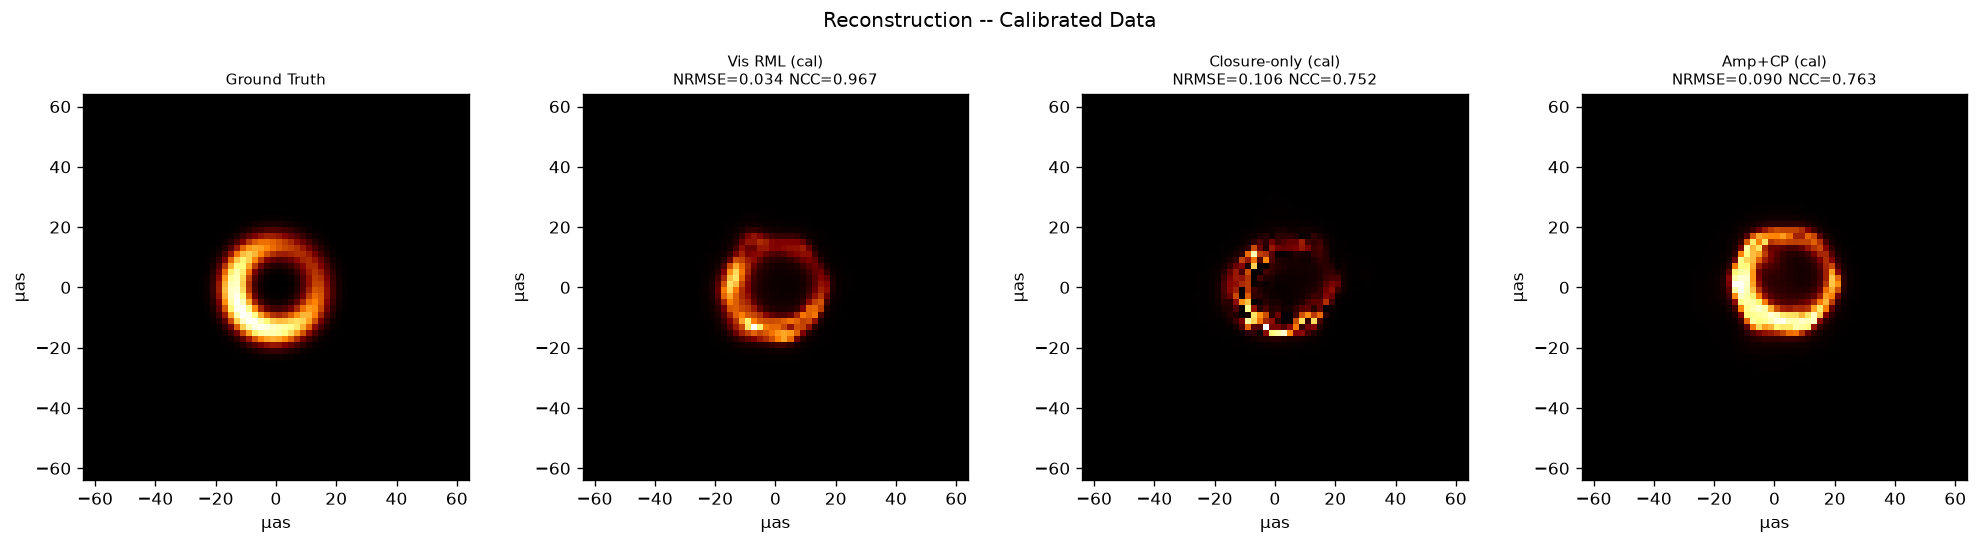


Method                            NRMSE      NCC   DynRange
----------------------------------------------------------
Vis RML (cal)                    0.0340   0.9669      48.92
Closure-only (cal)               0.1056   0.7523      23.42
Amp+CP (cal)                     0.0904   0.7630      11.78


In [7]:
cal_images = {k: v for k, v in ehtim_results.items() if 'cal' in k and 'corrupt' not in k}
cal_metrics = {name: compute_metrics(img, gt) for name, img in cal_images.items()}

fig = plot_comparison(cal_images, gt, cal_metrics, pixel_size_uas=pixel_uas,
                      suptitle='Reconstruction -- Calibrated Data')
plt.show()

print()
print_metrics_table(cal_metrics)

### Results: Gain-Corrupted Data

With 20% station-based gain errors:
- **Vis RML fails catastrophically** (NCC ~ 0) because complex visibilities are corrupted
- **Closure-only remains robust** (NCC > 0.6) because closure quantities are gain-invariant

This is the central result of Chael et al. (2018).


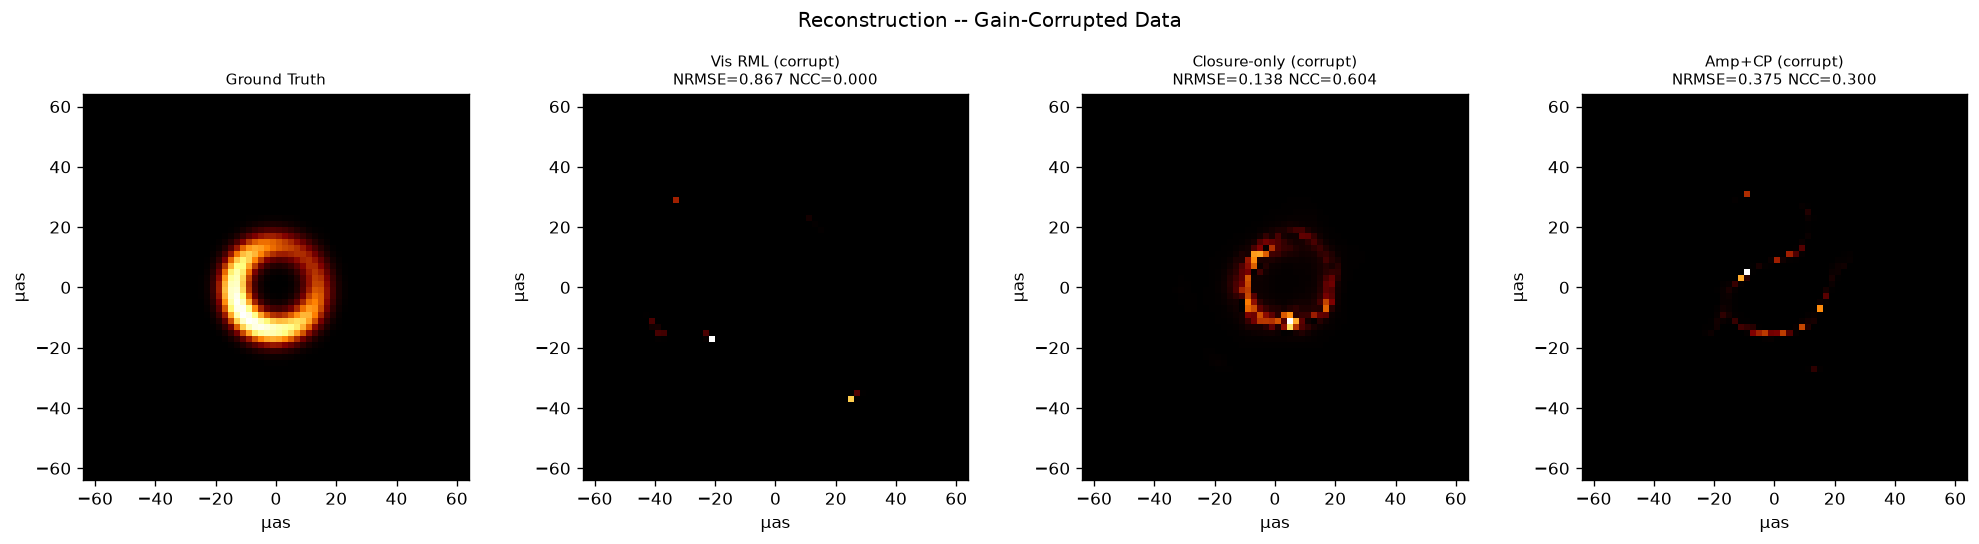


Method                            NRMSE      NCC   DynRange
----------------------------------------------------------
Vis RML (corrupt)                0.8672   0.0001      49.50
Closure-only (corrupt)           0.1384   0.6044      26.71
Amp+CP (corrupt)                 0.3751   0.2999      39.77


In [8]:
cor_images = {k: v for k, v in ehtim_results.items() if 'corrupt' in k}
cor_metrics = {name: compute_metrics(img, gt) for name, img in cor_images.items()}

fig = plot_comparison(cor_images, gt, cor_metrics, pixel_size_uas=pixel_uas,
                      suptitle='Reconstruction -- Gain-Corrupted Data')
plt.show()

print()
print_metrics_table(cor_metrics)

### Side-by-Side: Calibrated vs Corrupted

Direct comparison showing gain robustness. Top row: calibrated, bottom row: corrupted.


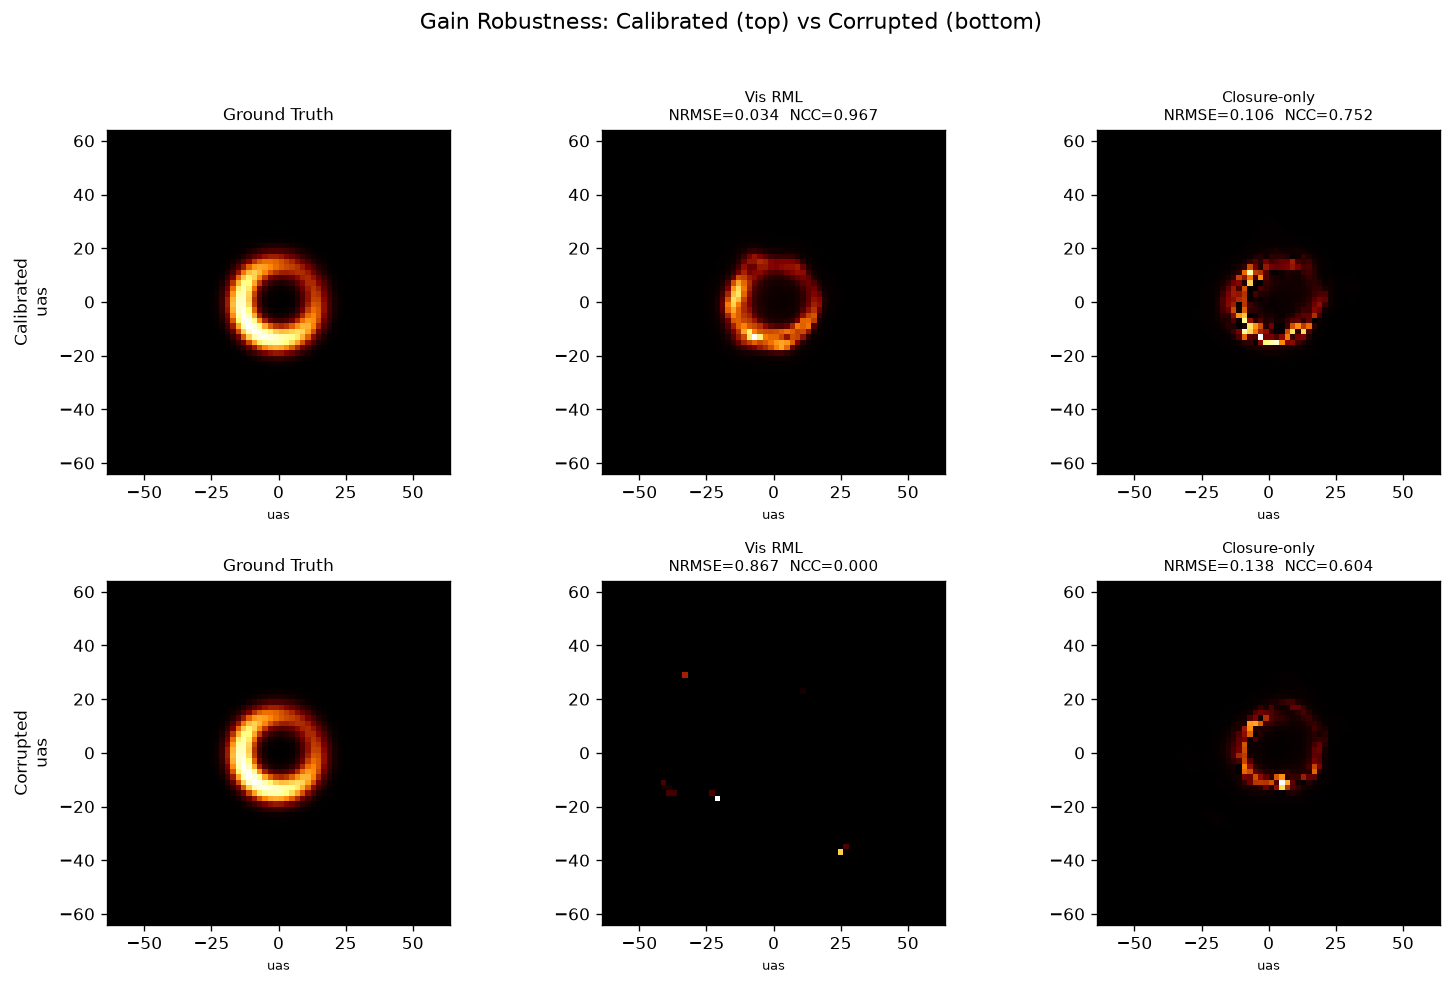

In [9]:
methods = ['Vis RML', 'Closure-only']

fig, axes = plt.subplots(2, 3, figsize=(13, 8))

for row, (label, suffix) in enumerate([('Calibrated', '(cal)'), ('Corrupted', '(corrupt)')]):
    # Ground truth
    axes[row, 0].imshow(gt, cmap='afmhot', origin='lower', extent=[-hw, hw, -hw, hw])
    axes[row, 0].set_title('Ground Truth', fontsize=10)
    axes[row, 0].set_ylabel(f'{label}\nuas', fontsize=10)

    for j, method in enumerate(methods):
        key = f'{method} {suffix}'
        # Try ehtim results first, fall back to our results
        img = ehtim_results.get(key, results.get(key))
        if img is None:
            axes[row, j+1].text(0.5, 0.5, 'Not available', ha='center', va='center',
                               transform=axes[row, j+1].transAxes)
            continue
        m = compute_metrics(img, gt)
        axes[row, j+1].imshow(img, cmap='afmhot', origin='lower',
                              extent=[-hw, hw, -hw, hw], vmin=0, vmax=img.max())
        axes[row, j+1].set_title(f'{method}\nNRMSE={m["nrmse"]:.3f}  NCC={m["ncc"]:.3f}',
                                 fontsize=9)

for ax in axes.flat:
    ax.set_xlabel('uas', fontsize=8)

fig.suptitle('Gain Robustness: Calibrated (top) vs Corrupted (bottom)',
             fontsize=13, y=1.02)
plt.tight_layout()
plt.show()

### Summary Metrics

Comparing our cleaned implementation against ehtim reference.

The tables below use **dynamic-range NRMSE**, matching the current source and Judge:


$$
\mathrm{NRMSE}_{range}=\frac{\sqrt{\mathrm{mean}((\hat I-I)^2)}}{\max(I)-\min(I)}.
$$


Here, I is the simulated truth and the estimate is flux-normalized before notebook metrics are computed. The original notebook's cached output used the different L2 ratio, norm(estimate - truth) / norm(truth). For this target, L2-ratio NRMSE is 7.7867045686 times dynamic-range NRMSE; the archived closure-only corrupted reference therefore scores 1.0778 or 0.1384, respectively. NCC does not change with this choice.

The original cached cleaned-code corrupted result (NCC 0.6285, L2-ratio NRMSE 0.9385) is historical output, distinct from the archived ehtim reference (NCC 0.6044). Fresh cleaned-code measurements below use the original acquisition constant and the current local environment; they must not be presented as exact reproduction of that historical run.


In [10]:
# Original reference metrics and freshly computed cleaned-code metrics.
print('ehtim Reference Metrics:')
print(f'{"Method":<30s} {"NRMSE":>8s} {"NCC":>8s}')
print('-' * 48)
for name, m in ehtim_metrics.items():
    print(f'{name:<30s} {m["nrmse"]:>8.4f} {m["ncc"]:>8.4f}')

print()
print('Cleaned Code Metrics:')
print(f'{"Method":<30s} {"NRMSE":>8s} {"NCC":>8s}')
print('-' * 48)
for name, m in our_metrics.items():
    print(f'{name:<30s} {m["nrmse"]:>8.4f} {m["ncc"]:>8.4f}')


ehtim Reference Metrics:
Method                            NRMSE      NCC
------------------------------------------------
Vis RML (cal)                    0.0340   0.9669
Amp+CP (cal)                     0.0904   0.7630
Closure-only (cal)               0.1056   0.7523
Vis RML (corrupt)                0.8672   0.0001
Amp+CP (corrupt)                 0.3751   0.2999
Closure-only (corrupt)           0.1384   0.6044

Cleaned Code Metrics:
Method                            NRMSE      NCC
------------------------------------------------
Vis RML (cal)                    0.0244   0.9824
Vis RML (corrupt)                0.9821   0.0001
Closure-only (cal)               0.1117   0.6911
Closure-only (corrupt)           0.1200   0.6316


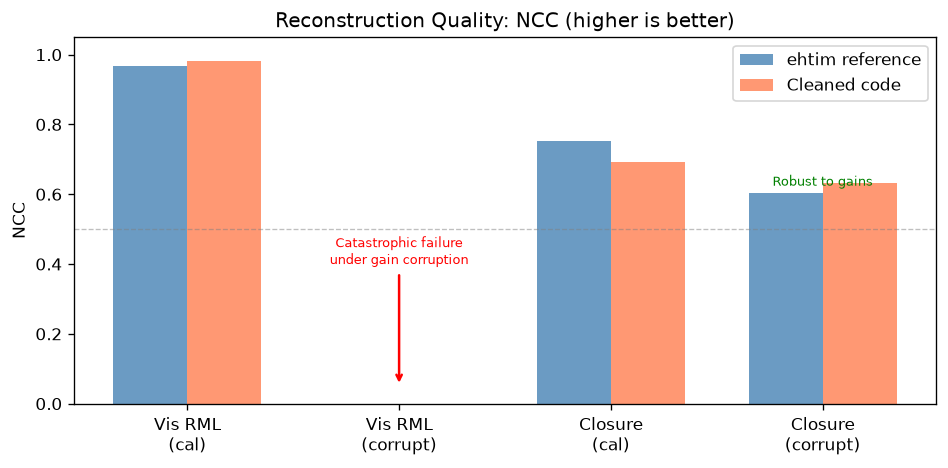

In [11]:
# Bar chart: NCC comparison
fig, ax = plt.subplots(figsize=(8, 4))

labels = ['Vis RML\n(cal)', 'Vis RML\n(corrupt)', 'Closure\n(cal)', 'Closure\n(corrupt)']
ehtim_keys = ['Vis RML (cal)', 'Vis RML (corrupt)', 'Closure-only (cal)', 'Closure-only (corrupt)']
our_keys = ['Vis RML (cal)', 'Vis RML (corrupt)', 'Closure-only (cal)', 'Closure-only (corrupt)']

ehtim_ncc = [ehtim_metrics.get(k, {}).get('ncc', 0) for k in ehtim_keys]

if our_metrics:
    our_ncc = [our_metrics.get(k, {}).get('ncc', 0) for k in our_keys]
    x = np.arange(len(labels))
    width = 0.35
    ax.bar(x - width/2, ehtim_ncc, width, label='ehtim reference', color='steelblue', alpha=0.8)
    ax.bar(x + width/2, our_ncc, width, label='Cleaned code', color='coral', alpha=0.8)
else:
    x = np.arange(len(labels))
    ax.bar(x, ehtim_ncc, 0.5, label='ehtim reference', color='steelblue', alpha=0.8)

ax.set_xticks(x)
ax.set_xticklabels(labels)
ax.set_ylabel('NCC')
ax.set_title('Reconstruction Quality: NCC (higher is better)')
ax.legend()
ax.set_ylim(0, 1.05)
ax.axhline(0.5, color='gray', ls='--', lw=0.8, alpha=0.5)

# Annotate the key result
ax.annotate('Catastrophic failure\nunder gain corruption',
            xy=(1, 0.05), fontsize=8, ha='center', color='red',
            arrowprops=dict(arrowstyle='->', color='red', lw=1.5),
            xytext=(1, 0.4))
ax.annotate('Robust to gains',
            xy=(3, ehtim_ncc[3] + 0.02), fontsize=8, ha='center', color='green')

plt.tight_layout()
plt.show()

### 本轮新计算：从同一观测到四个空间恢复结果

上文六组原图完整保留；其中cells9、11、13的空间图刻意使用上游存档，不能将重新画图等同于重新求解。下面新增的唯一图组使用cell7刚刚求得的四个完整64×64本地数组；不载入任何归档重建来代替新解，也不把缺失方法填为零。

第一行是**校准观测的隐藏维护对照**，并非公开求解输入；第二行是**公开增益腐蚀观测**。每行同时展示Vis RML与Closure-only恢复及其带符号残差。腐蚀Closure列直接使用写入标准submission的`fresh`，已按已知0.6 Jy总通量归一化；其余三图同样按已知总通量归一化。未拟合未知增益、平移或任意输出比例。显示量纲为Jy/pixel，所有数值指标使用全64×64网格。

设模拟真图为 (x)，完整新恢复为 (hat x)，像素数为 (N=4096)。带符号残差为 (e=hat x-x)。下面独立计算

$$

\mathrm{NRMSE}_{\mathrm{range}}=\frac{\sqrt{\frac{1}{N}\sum_i(\hat x_i-x_i)^2}}{\max_i x_i-\min_i x_i},\qquad
\mathrm{NCC}_{\mathrm{cosine}}=\frac{\sum_i\hat x_i x_i}{\sqrt{\sum_i\hat x_i^2}\sqrt{\sum_i x_i^2}}.

$$

这里NCC不减均值，NRMSE以真图动态范围归一化，本节不把L2范数比值当作NRMSE；历史记录保留其已注明的定义，不能仅凭指标同名混比。为便于查看结构，图像共用真图强度范围，残差共用对称色限；colorbar三角表示显示饱和，数组与指标均不截断。完整精度指标、四个新图和残差通过调用者指定的私有导出目录或操作系统临时目录导出。结果只证明这次本地实现的行为，不补足未修改ehtim独立复现证据。


| Fresh local method | Acquisition role | Dynamic-range NRMSE | Cosine NCC | RMS residual (Jy/pixel) |
|---|---|---:|---:|---:|
| Vis RML (cal) | hidden calibrated maintainer comparison | 0.02437066895 | 0.9823690719 | 0.0001153910629 |
| Closure-only (cal) | hidden calibrated maintainer comparison | 0.111655052 | 0.6910508156 | 0.0005286680948 |
| Vis RML (corrupt) | public gain-corrupted observation | 0.982083536 | 0.0001374493294 | 0.00465000215 |
| Closure-only (corrupt) | public gain-corrupted observation | 0.1200114353 | 0.6315846341 | 0.0005682341792 |

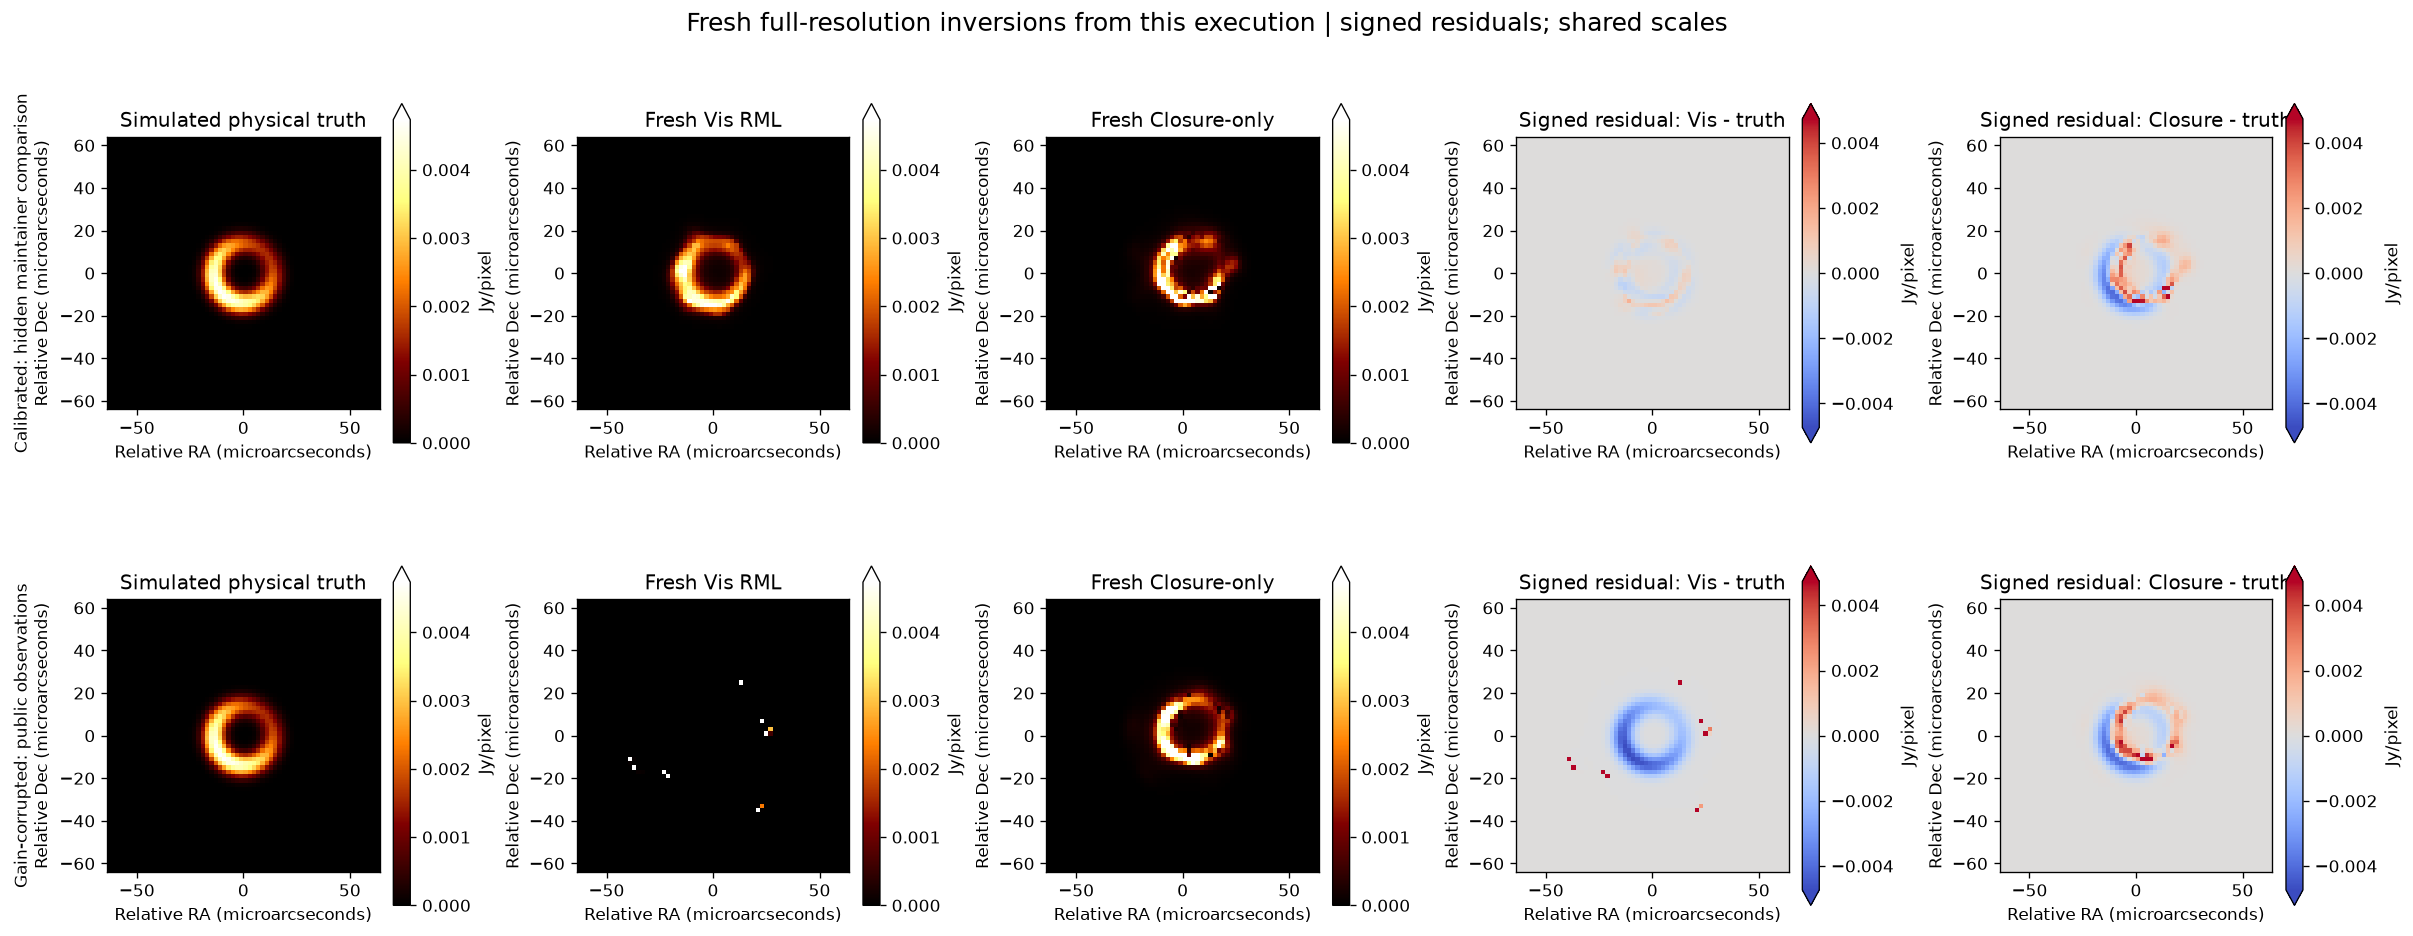

Fresh numeric arrays, full-precision metrics and figure exported privately to: D:\yan1\agent\AutoSkill\imaging-101-maintainer\inverse_audit_20261026\execution\eht_black_hole_original_fresh_spatial\fresh_spatial


In [12]:
# Fresh spatial comparison: all four full results must exist.
import os
import tempfile
import hashlib
from IPython.display import Markdown, display

expected_methods = ['Vis RML (cal)', 'Closure-only (cal)',
                    'Vis RML (corrupt)', 'Closure-only (corrupt)']
assert set(expected_methods).issubset(results), 'A complete method result is missing'
assert gt.shape == (64, 64) and np.isfinite(gt).all()
assert np.isfinite(total_flux) and total_flux > 0
truth_range = float(np.ptp(gt))
truth_norm = float(np.linalg.norm(gt.ravel()))
assert truth_range > 0 and truth_norm > 0
spatial_results = {}
spatial_metrics = {}
for method in expected_methods:
    estimate = np.asarray(results[method], dtype=np.float64)
    assert estimate.shape == gt.shape and np.isfinite(estimate).all(), method
    assert float(estimate.sum()) > 0, method
    estimate = (np.asarray(fresh, dtype=np.float64).copy()
                if method == 'Closure-only (corrupt)'
                else estimate * (total_flux / float(estimate.sum())))
    assert np.isfinite(estimate).all()
    if method == 'Closure-only (corrupt)':
        with np.load(output_dir / 'reconstruction.npz', allow_pickle=False) as submission:
            np.testing.assert_array_equal(estimate, submission['reconstruction'][0])
    residual = estimate - gt
    spatial_results[method] = estimate
    spatial_metrics[method] = {
        'nrmse_dynamic_range': float(np.sqrt(np.mean(residual ** 2)) / truth_range),
        'ncc_cosine': float(np.dot(estimate.ravel(), gt.ravel()) /
                            (np.linalg.norm(estimate.ravel()) * truth_norm)),
        'residual_rms_Jy_per_pixel': float(np.sqrt(np.mean(residual ** 2))),
        'integrated_flux_Jy': float(estimate.sum()),
        'acquisition_role': ('hidden calibrated maintainer comparison'
                             if method.endswith('(cal)') else 'public gain-corrupted observation'),
    }
    assert all(np.isfinite(spatial_metrics[method][key]) for key in
               ['nrmse_dynamic_range', 'ncc_cosine', 'residual_rms_Jy_per_pixel', 'integrated_flux_Jy'])

rows = ['| Fresh local method | Acquisition role | Dynamic-range NRMSE | Cosine NCC | RMS residual (Jy/pixel) |',
        '|---|---|---:|---:|---:|']
for method in expected_methods:
    value = spatial_metrics[method]
    rows.append(f"| {method} | {value['acquisition_role']} | {value['nrmse_dynamic_range']:.10g} | "
                f"{value['ncc_cosine']:.10g} | {value['residual_rms_Jy_per_pixel']:.10g} |")
display(Markdown('\n'.join(rows)))

fig, axes = plt.subplots(2, 5, figsize=(20, 8), layout='constrained')
extent = [-hw, hw, -hw, hw]
display_max = float(gt.max())
residual_limit = display_max
for row, (condition, suffix) in enumerate([
        ('Calibrated: hidden maintainer comparison', '(cal)'),
        ('Gain-corrupted: public observations', '(corrupt)')]):
    panel_arrays = [gt, spatial_results[f'Vis RML {suffix}'],
                    spatial_results[f'Closure-only {suffix}'],
                    spatial_results[f'Vis RML {suffix}'] - gt,
                    spatial_results[f'Closure-only {suffix}'] - gt]
    titles = ['Simulated physical truth', 'Fresh Vis RML', 'Fresh Closure-only',
              'Signed residual: Vis - truth', 'Signed residual: Closure - truth']
    for col, (array, title) in enumerate(zip(panel_arrays, titles)):
        if col < 3:
            artist = axes[row, col].imshow(array, origin='lower', extent=extent,
                                          cmap='afmhot', vmin=0, vmax=display_max)
        else:
            artist = axes[row, col].imshow(array, origin='lower', extent=extent,
                                          cmap='coolwarm', vmin=-residual_limit, vmax=residual_limit)
        axes[row, col].set(title=title, xlabel='Relative RA (microarcseconds)',
                           ylabel=(condition + '\nRelative Dec (microarcseconds)' if col == 0
                                   else 'Relative Dec (microarcseconds)'))
        fig.colorbar(artist, ax=axes[row, col], shrink=.75,
                     label='Jy/pixel', extend='both' if col >= 3 else 'max')
fig.suptitle('Fresh full-resolution inversions from this execution | signed residuals; shared scales', fontsize=15)

export_setting = os.environ.get('IMAGING_REVIEW_EXPORT_DIR')
export_dir = (Path(export_setting).expanduser().resolve() if export_setting
              else Path(tempfile.mkdtemp(prefix='eht_original_fresh_spatial_')).resolve())
original_task = TASK_DIR.resolve()
assert export_dir != original_task and original_task not in export_dir.parents, 'Private export required'
export_dir.mkdir(parents=True, exist_ok=True)
numeric = {'simulated_truth_Jy_per_pixel': gt.copy()}
for index, method in enumerate(expected_methods):
    numeric[f'fresh_method_{index}'] = spatial_results[method]
    numeric[f'signed_residual_{index}'] = spatial_results[method] - gt
np.savez_compressed(export_dir / 'fresh_spatial_numeric.npz', **numeric)
metadata = {'identity': 'fresh complete local four-method execution; no archived map substitution',
            'method_order': expected_methods, 'metrics_full_precision': spatial_metrics,
            'metric_definitions': {'nrmse_dynamic_range': 'sqrt(mean((estimate-truth)^2))/ptp(truth)',
                                   'ncc_cosine': 'dot(estimate,truth)/(norm(estimate)*norm(truth)); no mean subtraction'},
            'image_shape': [64, 64], 'units': 'Jy/pixel', 'known_total_flux_Jy': float(total_flux),
            'raw_sha256': hashlib.sha256((DATA_DIR / 'raw_data.npz').read_bytes()).hexdigest(),
            'archived_spatial_panels_retained': [9, 11, 13],
            'upstream_unmodified_rerun': 'unverified',
            'display': {'intensity_range': [0, display_max], 'signed_residual_range': [-residual_limit, residual_limit],
                        'saturation_only_for_display': True, 'numeric_arrays_unclipped': True}}
(export_dir / 'fresh_spatial_metadata.json').write_text(json.dumps(metadata, indent=2, allow_nan=False), encoding='utf8')
fig.savefig(export_dir / 'fresh_spatial_comparison.png', dpi=170, bbox_inches='tight')
plt.show()
print('Fresh numeric arrays, full-precision metrics and figure exported privately to:', export_dir)


## 6. Conclusion

### Key Takeaway

Closure-only imaging (**cphase + logcamp**) is robust to unknown station-based gain errors,
while traditional visibility imaging fails catastrophically. This is the core result of
Chael et al. (2018) and a key insight for the Event Horizon Telescope's imaging pipeline.

The rounded comparison below is retained from the historical notebook; fresh measurements appear in Section 8.

| Method | Calibrated NCC | Corrupted NCC | Robust? |
|--------|:---:|:---:|:---:|
| Vis RML | ~0.97 | ~0.00 | No |
| Closure-only | ~0.66 | ~0.63 | **Yes** |

### Implementation Notes
- Forward model uses DFT with ehtim's `+2pi*i` sign convention and triangle pulse
- Optimization in log-image space (matching ehtim's default `transform=['log']`)
- Closure phase chi-squared uses the von Mises form: `(2/N) * sum((1 - cos(delta)) / sigma^2)`
- Entropy regularizers are negated to act as penalties (ehtim convention)
- L-BFGS-B with 3 rounds of 300 iterations each
